In [428]:
import pandas as pd
import seaborn as sb
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.cluster import k_means, DBSCAN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [429]:
ss = StandardScaler()
df = pd.read_excel('Dry_Bean_Dataset.xlsx')
pca = PCA()

Data Preparation

In [ ]:
# df.isna().sum() (no NAs)
# df.duplicated().sum() (no duplicates)
# df.map(lambda x: type(x) == int or type(x) == float).sum() all numbers are filled

# Statistical analysis
df.skew()
df.describe()

,sample_id,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,0.0
mean,6806.000000,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063,NaN
std,3929.301592,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366,NaN
min,1.000000,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687,NaN
25%,3403.500000,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703,NaN
50%,6806.000000,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386,NaN
75%,10208.500000,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883,NaN
max,13611.000000,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733,NaN


KMeans with normalization

In [ ]:
# Kmeans Train the dataset on the data an output the groups
x = df.iloc[:,:-1]
x = ss.fit_transform(x)
km = k_means(x, n_clusters=7, random_state=41)
km[-2] #resulting classifications

df_k = pd.DataFrame(
    data=[
        df.iloc[:,0],
        km[-2]
    ],
    index=["Sample_id","Group"],
).transpose()

df_k # model results

,Sample_id,Group
0,1,0
1,2,6
2,3,1
3,4,0
4,5,2
...,...,...
13606,13607,0
13607,13608,2
13608,13609,1
13609,13610,2


Kmeans with pca

In [432]:
# Kmeans Train the dataset on the data an output the groups
x_p = ss.fit_transform(x)
pca_1 = pca.fit(x)
x_p = pca_1.fit_transform(x) # pca_1.explained_variance_
km = k_means(x_p[:,:-9], n_clusters=7, random_state=41)
km[-2] #resulting classifications

df_kp = pd.DataFrame(
    data=[
        df.iloc[:,0],
        km[-2]
    ],
    index=["Sample_id","Group"],
).transpose()

df_kp # (df_k == df_kp).sum() #num of matches


,Sample_id,Group
0,1,3
1,2,5
2,3,4
3,4,3
4,5,2
...,...,...
13606,13607,3
13607,13608,2
13608,13609,4
13609,13610,2


DBSCAN with normalization

In [ ]:
x_b = df.iloc[:,:-1]
x_b = ss.fit_transform(x_b)
dbs = DBSCAN(eps=.5, min_samples=7, metric='euclidean', algorithm='auto')
m = dbs.fit_predict(x_b) # np.unique(dbs.fit_predict(x))
m # results

array([-1,  0, -1, ..., -1, -1, -1], shape=(13611,))

DBSCAN with normalization and PCA

In [482]:
x_bp = df.iloc[:,:-1]
x_bp = ss.fit_transform(x_bp)
x_bp = pca.fit_transform(x_bp)
dbs = DBSCAN(eps=.5, min_samples=15, metric='euclidean', algorithm='auto')
npca = dbs.fit_predict(x_bp[:,:-10]) # np.unique(dbs.fit_predict(x))
npca # (m == npca).sum() # difference between the results
# np.unique(npca)

array([-1,  0, -1, ..., -1, -1, -1], shape=(13611,))

data visualization

In [ ]:
# df_npca = np.column_stack((df,npca))
# df_npca = pd.DataFrame(df_npca)

# df_npca.columns = ['sample_id', 'Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
#        'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
#        'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
#        'ShapeFactor3', 'ShapeFactor4', 'Class', 'classpred']

df_npca = df_npca.drop(['Class'], axis=1)
df_npca = df_npca[df_npca['classpred'] != -1]
df_npca = df_npca.reset_index(drop=['index'])

<Axes: xlabel='0', ylabel='1'>

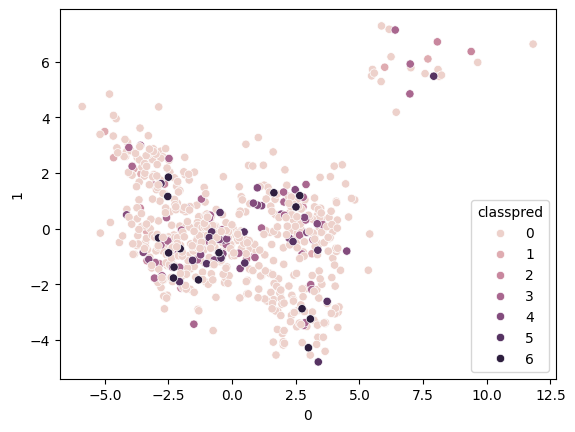

In [487]:
pca2 = PCA(n_components=2)
gpca = ss.fit_transform(x)
gpca = pca2.fit_transform(gpca)
gpca = pd.DataFrame(gpca)

sb.scatterplot(data=gpca, x=0, y=1, hue=df_npca.iloc[:,-1])